In [1]:
# Make helpers.py importable, whatever folder Jupyter started the kernel in
import sys
from pathlib import Path
_candidates = [Path.cwd(), Path.cwd() / "code",
               *Path.cwd().glob("*/code"), *Path.cwd().glob("*/*/code")]
CODE = next(p for p in _candidates if (p / "helpers.py").is_file())
sys.path.insert(0, str(CODE))

In [2]:
# Generated with Claude (Anthropic): gradient boosting of underfunding on the same
# variables and the same country-grouped folds as the logistic regression.
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.metrics import roc_auc_score

from helpers import find_root, country_folds

ROOT = find_root()
PROCESSED = ROOT / "data" / "processed"
FIGURES = ROOT / "figures"

df = pd.read_csv(PROCESSED / "analysis_table.csv")

# Trees need numbers: each sector gets a code (0, 1, 2...), treated as a category
df["sector_code"] = df["cluster"].astype("category").cat.codes

FEATURES = ["sector_code", "log_gdp_pc_lag", "gov_effectiveness_lag",
            "log_reports_lag", "year", "log_requirements"]
X = df[FEATURES]
y = df["underfunded"]

# Same 5 country groups as in 04_logistic_regression
df["fold"] = country_folds(df)
print(X.shape)

(7413, 6)


In [3]:
# Nested cross-validation:
# - outer loop: the 5 country groups, to measure performance on unseen countries
# - inner loop: inside the training countries only, choose the tree settings
GRID = {"max_depth": [2, 3, 4],          # size of each tree
        "learning_rate": [0.05, 0.1],    # how much each new tree corrects
        "max_iter": [100, 300]}          # number of trees

predictions = pd.Series(np.nan, index=df.index)
chosen = []
for k in sorted(df["fold"].unique()):
    train, test = df["fold"] != k, df["fold"] == k
    search = GridSearchCV(
        HistGradientBoostingClassifier(categorical_features=[0], random_state=0),
        GRID, cv=GroupKFold(n_splits=4), scoring="roc_auc")
    search.fit(X[train], y[train], groups=df.loc[train, "countryCode"])
    predictions[test] = search.predict_proba(X[test])[:, 1]
    chosen.append({"fold": k, **search.best_params_,
                   "AUC inside training countries": round(search.best_score_, 3)})

pd.DataFrame(chosen)

,fold,learning_rate,max_depth,max_iter,AUC inside training countries
0,0,0.05,3,100,0.697
1,1,0.05,3,100,0.687
2,2,0.05,2,100,0.694
3,3,0.05,3,100,0.714
4,4,0.10,4,100,0.719


In [4]:
# Compare with the logistic regression (same countries, same folds)
cv_logit = pd.read_csv(FIGURES / "table_cv_logit.csv", index_col=0)

cv_all = cv_logit.copy()
cv_all.loc["Gradient boosting"] = [roc_auc_score(y, predictions),
                                   ((predictions >= 0.5) == y).mean()]
cv_all = cv_all.round(3)
cv_all.to_csv(FIGURES / "table_cv_comparison.csv")
cv_all

,AUC,Accuracy
0. Controls only,0.595,0.639
1. Sector,0.688,0.688
2. Country,0.600,0.638
3. Sector + country,0.697,0.688
Always 'underfunded',0.500,0.636
Gradient boosting,0.698,0.700


In [5]:
# Permutation importance on unseen countries: shuffle one variable at a time
# and measure how much the AUC drops (bigger drop = more important variable)
from sklearn.inspection import permutation_importance

SETTINGS = {"learning_rate": 0.05, "max_depth": 3, "max_iter": 100}  # most chosen settings
LABELS = {"sector_code": "Sector",
          "log_gdp_pc_lag": "GDP per capita (t-1)",
          "gov_effectiveness_lag": "Government effectiveness (t-1)",
          "log_reports_lag": "Humanitarian attention (t-1)",
          "year": "Year",
          "log_requirements": "Appeal size (log requirements)"}

drops = []
for k in sorted(df["fold"].unique()):
    train, test = df["fold"] != k, df["fold"] == k
    model = HistGradientBoostingClassifier(categorical_features=[0], random_state=0, **SETTINGS)
    model.fit(X[train], y[train])
    result = permutation_importance(model, X[test], y[test], scoring="roc_auc",
                                    n_repeats=10, random_state=0)
    drops.append(pd.Series(result.importances_mean, index=FEATURES))

importance = pd.concat(drops, axis=1)
importance = pd.DataFrame({
    "AUC loss (mean over folds)": importance.mean(axis=1),
    "Min over folds": importance.min(axis=1),
    "Max over folds": importance.max(axis=1),
}).rename(index=LABELS).sort_values("AUC loss (mean over folds)", ascending=False).round(3)
importance.to_csv(FIGURES / "table_permutation_importance.csv")
importance

,AUC loss (mean over folds),Min over folds,Max over folds
Sector,0.161,0.129,0.197
Year,0.056,0.051,0.060
Humanitarian attention (t-1),0.024,0.008,0.034
GDP per capita (t-1),0.004,-0.011,0.017
Appeal size (log requirements),0.004,-0.004,0.007
Government effectiveness (t-1),-0.002,-0.007,0.001


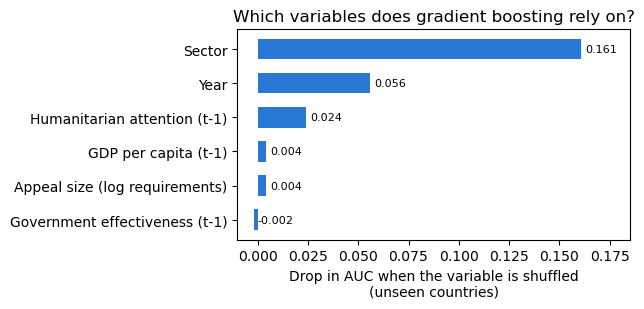

In [6]:
# Bar chart of permutation importance
import matplotlib.pyplot as plt

BLUE = "#2a78d6"
shown = importance.iloc[::-1]          # most important at the top
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.barh(shown.index, shown["AUC loss (mean over folds)"], color=BLUE, height=0.6)
for i, v in enumerate(shown["AUC loss (mean over folds)"]):
    ax.text(v + 0.002, i, f"{v:.3f}", va="center", fontsize=8)
ax.set_xlim(right=shown["AUC loss (mean over folds)"].max() * 1.15)
ax.set_xlabel("Drop in AUC when the variable is shuffled\n(unseen countries)")
ax.set_title("Which variables does gradient boosting rely on?")
fig.tight_layout()
fig.savefig(FIGURES / "fig_permutation_importance.pdf")
plt.show()

In [7]:
# Same comparison as in 04 (controls / sector / country / both), with gradient
# boosting: can a flexible model get more out of country characteristics?
CONTROLS = ["year", "log_requirements"]
COUNTRY = ["log_gdp_pc_lag", "gov_effectiveness_lag", "log_reports_lag"]
variable_sets = {
    "0. Controls only": CONTROLS,
    "1. Sector": ["sector_code"] + CONTROLS,
    "2. Country": COUNTRY + CONTROLS,
    "3. Sector + country": ["sector_code"] + COUNTRY + CONTROLS,
}
target = df["underfunded"]

def boosting_cv(columns):
    """Nested country-grouped cross-validation of gradient boosting on the given
    columns; returns the predicted probability of each row (unseen countries)."""
    categorical = [c == "sector_code" for c in columns]   # sector is a category
    preds = pd.Series(np.nan, index=df.index)
    for k in sorted(df["fold"].unique()):
        train, test = df["fold"] != k, df["fold"] == k
        search = GridSearchCV(
            HistGradientBoostingClassifier(categorical_features=categorical, random_state=0),
            GRID, cv=GroupKFold(n_splits=4), scoring="roc_auc")
        search.fit(df.loc[train, columns], target[train], groups=df.loc[train, "countryCode"])
        preds[test] = search.predict_proba(df.loc[test, columns])[:, 1]
    return preds

rows = {}
for name, columns in variable_sets.items():
    rows[name] = {"AUC, logistic regression": cv_logit.loc[name, "AUC"],
                  "AUC, gradient boosting": roc_auc_score(target, boosting_cv(columns))}

cv_by_model = pd.DataFrame(rows).T.round(3)
cv_by_model.to_csv(FIGURES / "table_cv_by_model.csv")
cv_by_model

,"AUC, logistic regression","AUC, gradient boosting"
0. Controls only,0.595,0.595
1. Sector,0.688,0.704
2. Country,0.600,0.603
3. Sector + country,0.697,0.698
